В качестве целевой переменной выбрана стоимость поездки fare_amount, поскольку она является числовым показателем и позволяет исследовать распределение стоимости услуг такси.

В качестве временного признака выбран столбец pickup_datetime, содержащий дату и время начала поездки. Для анализа временной динамики выбран месячный период, позволяющий сгладить краткосрочные колебания и выявить общие тенденции.

В качестве группировочного признака выбран passenger_count — количество пассажиров. Значения этого столбца повторяются, поскольку множество поездок может иметь одинаковое количество пассажиров. Это позволяет сравнивать характеристики поездок между группами.

In [1]:
import pandas as pd

df = pd.read_parquet("E:/laba_results/clean_final.parquet")

print("Размер данных:", df.shape)
print("\nТипы столбцов:")
print(df.dtypes)

df.head()

Размер данных: (55418645, 8)

Типы столбцов:
key                             str
fare_amount                 float64
pickup_datetime      datetime64[us]
pickup_longitude            float64
pickup_latitude             float64
dropoff_longitude           float64
dropoff_latitude            float64
passenger_count               int64
dtype: object


,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2009-03-23 10:54:00.000000117,6.9,2009-03-23 13:54:00,-73.999913,40.743288,-73.989928,40.733318,1
1,2009-08-05 09:25:58.0000002,22.5,2009-08-05 13:25:58,-73.981918,40.743336,-73.981816,40.668663,1
2,2009-12-31 21:54:49.0000005,20.9,2010-01-01 00:54:49,-73.959789,40.692228,-73.960748,40.760715,1
3,2013-01-30 07:05:23.0000001,4.5,2013-01-30 11:05:23,-73.976342,40.755440,-73.975207,40.763408,1
4,2012-11-16 09:26:00.000000133,38.8,2012-11-16 13:26:00,-73.872912,40.774037,-73.885227,40.771887,1


In [2]:
target = df['fare_amount']

summary = {
    'Число наблюдений': target.shape[0],
    'Число пропусков': target.isna().sum(),
    'Минимум': round(target.min(), 2),
    'Первый квартиль': round(target.quantile(0.25), 2),
    'Медиана': round(target.median(), 2),
    'Среднее': round(target.mean(), 2),
    'Третий квартиль': round(target.quantile(0.75), 2),
    'Максимум': round(target.max(), 2),
    'Коэффициент асимметрии (skew)': round(target.skew(), 3)
}

print("Сводка по целевой переменной 'fare_amount':\n")
for key, value in summary.items():
    print(f"{key}: {value}")

if summary['Коэффициент асимметрии (skew)'] > 0:
    print("\nСкошенность: вправо (положительная асимметрия)")
elif summary['Коэффициент асимметрии (skew)'] < 0:
    print("\nСкошенность: влево (отрицательная асимметрия)")
else:
    print("\nСкошенность: распределение симметрично")

Сводка по целевой переменной 'fare_amount':

Число наблюдений: 55418645
Число пропусков: 0
Минимум: 0.0
Первый квартиль: 6.0
Медиана: 8.5
Среднее: 11.34
Третий квартиль: 12.5
Максимум: 999.99
Коэффициент асимметрии (skew): 4.235

Скошенность: вправо (положительная асимметрия)


In [3]:
import pandas as pd

print("Диапазон дат:", df['pickup_datetime'].min(), "—", df['pickup_datetime'].max())

# 1. Период — календарный месяц (как выбрано на шаге 2)
df['period'] = df['pickup_datetime'].dt.to_period('M')

agg = (
    df.groupby('period')['fare_amount']
      .agg(n_records='size', median_fare='median', mean_fare='mean')
)

full_index = pd.period_range(agg.index.min(), agg.index.max(), freq='M')
series = agg.reindex(full_index)

series['n_records'] = series['n_records'].fillna(0).astype(int)
series.index.name = 'period'

print("Всего периодов:", len(series))
print("Пустых периодов:", (series['n_records'] == 0).sum())

series.round(2).to_csv('../data/period_series.csv')

n = len(series)
mid = n // 2
table2 = pd.concat([
    series.iloc[:3],
    series.iloc[mid-1:mid+2],
    series.iloc[-3:]
]).round(2)

table2

Диапазон дат: 2009-01-01 03:00:27 — 2015-07-01 02:59:54
Всего периодов: 79
Пустых периодов: 0


,n_records,median_fare,mean_fare
period,,,
2009-01,700998,7.3,9.62
2009-02,669534,7.7,9.75
2009-03,720437,7.7,10.02
2012-03,803892,7.7,10.44
2012-04,776082,8.1,10.54
2012-05,775289,8.1,10.80
2015-05,660736,10.0,13.58
2015-06,614574,9.5,13.48
2015-07,3250,10.0,13.42


In [4]:
import pandas as pd

shares = df['passenger_count'].value_counts(normalize=True).sort_index()
RARE_SHARE = 0.01
rare = shares[shares < RARE_SHARE].index.tolist()
print("Доли групп:\n", shares.round(4))
print("Редкие группы:", rare)

fare_na = df['fare_amount'].isna()
table3 = (
    df.groupby('passenger_count')['fare_amount']
      .agg(n='size', median='median', mean='mean')
)
table3['na_share'] = fare_na.groupby(df['passenger_count']).mean()
table3['share'] = table3['n'] / len(df)
table3['rare'] = table3.index.isin(rare)
table3 = table3.rename(columns={
    'n': 'Число', 'median': 'Медиана', 'mean': 'Среднее',
    'na_share': 'Доля пропусков', 'share': 'Доля в данных', 'rare': 'Редкая'
})
table3.round(3)

Доли групп:
 passenger_count
0      0.0035
1      0.6917
2      0.1475
3      0.0439
4      0.0213
5      0.0709
6      0.0212
7      0.0000
8      0.0000
9      0.0000
34     0.0000
49     0.0000
129    0.0000
208    0.0000
Name: proportion, dtype: float64
Редкие группы: [0, 7, 8, 9, 34, 49, 129, 208]


,Число,Медиана,Среднее,Доля пропусков,Доля в данных,Редкая
passenger_count,,,,,,
0,195415,7.3,9.015,0.0,0.004,True
1,38334033,8.5,11.213,0.0,0.692,False
2,8174602,8.5,11.828,0.0,0.148,False
3,2432455,8.5,11.542,0.0,0.044,False
4,1178741,8.5,11.767,0.0,0.021,False
5,3928864,8.5,11.209,0.0,0.071,False
6,1174420,9.0,12.128,0.0,0.021,False
7,15,14.5,31.789,0.0,0.000,True
8,9,8.0,29.981,0.0,0.000,True


In [5]:
key = df['passenger_count'].where(~df['passenger_count'].isin(rare), -1)

diagram = df.groupby(key)['fare_amount'].agg(n='size', median='median', mean='mean')
diagram.index = ['прочие' if g == -1 else str(g) for g in diagram.index]
diagram.round(2)

,n,median,mean
прочие,195530,7.3,9.02
1,38334033,8.5,11.21
2,8174602,8.5,11.83
3,2432455,8.5,11.54
4,1178741,8.5,11.77
5,3928864,8.5,11.21
6,1174420,9.0,12.13


In [6]:
pivot = (
    df['fare_amount']
      .groupby([key.rename('group'), df['pickup_datetime'].dt.year.rename('year')])
      .median()
      .unstack('year')
)
pivot.index = ['прочие' if g == -1 else str(g) for g in pivot.index]
pivot.round(2)

year,2009,2010,2011,2012,2013,2014,2015
прочие,3.3,6.9,7.3,7.3,13.85,10.0,8.5
1,7.7,7.7,7.7,8.1,9.00,9.5,9.5
2,7.8,7.7,8.1,8.5,9.50,10.0,9.5
3,7.7,7.7,8.1,8.5,9.50,9.5,9.5
4,8.1,8.1,8.1,8.5,9.50,10.0,10.0
5,7.7,7.7,8.1,8.5,9.50,9.5,9.5
6,7.7,7.7,8.1,8.5,9.50,9.5,9.5


In [7]:
import sys
import importlib
import pandas as pd
from IPython.display import display

sys.path.append("../src")
import eda
importlib.reload(eda)

s = df['fare_amount']
n_total = len(s)

# Правило 1: межквартильный размах
mask_iqr, n_iqr = eda.iqr_outliers(s, k=1.5)

# Правило 2: предметное ограничение (стоимость поездки больше 0 и не выше 200 USD)
mask_dom, n_dom = eda.domain_outliers(s, low=0.0, high=200.0)

# Пересечение: строки, отмеченные обоими правилами
mask_both = mask_iqr & mask_dom
n_both = int(mask_both.sum())

# Границы IQR и контрольные счётчики для текста
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
print(f"Q1={q1}, Q3={q3}, IQR={iqr}, границы IQR: [{q1 - 1.5*iqr:.2f}; {q3 + 1.5*iqr:.2f}]")
print("Стоимость <= 0:", int((s <= 0).sum()))
print("Стоимость > 200:", int((s > 200).sum()))
print("Только IQR:", n_iqr - n_both, "| только предметное ограничение:", n_dom - n_both)

# Таблица 4
table4 = pd.DataFrame({
    'Правило': ['Межквартильный размах', 'Предметное ограничение', 'Пересечение'],
    'Число отмеченных': [n_iqr, n_dom, n_both],
    'Доля, %': [round(100 * n_iqr / n_total, 3),
                round(100 * n_dom / n_total, 3),
                round(100 * n_both / n_total, 3)],
    'Совпало со вторым': [n_both, n_both, '—'],
})
display(table4)

Q1=6.0, Q3=12.5, IQR=6.5, границы IQR: [-3.75; 22.25]
Стоимость <= 0: 1380
Стоимость > 200: 1641
Только IQR: 4771460 | только предметное ограничение: 1380


,Правило,Число отмеченных,"Доля, %",Совпало со вторым
0,Межквартильный размах,4773101,8.613,1641
1,Предметное ограничение,3021,0.005,1641
2,Пересечение,1641,0.003,—


In [8]:
import time
from statistics import median

import numpy as np
from IPython.display import display

values = df["fare_amount"].to_numpy(dtype=np.float64)

print("Число значений:", f"{values.size:,}".replace(",", " "))
print("Размер массива, ГБ:", round(values.nbytes / 1e9, 2))

Число значений: 55 418 645
Размер массива, ГБ: 0.44


In [9]:
def mean_loop(xs):
    total = 0.0
    for x in xs:
        total += x
    return total / len(xs)


def mean_numpy(arr):
    return arr.sum() / arr.size


res_loop = mean_loop(values)
res_np = mean_numpy(values)

print(f"Цикл:  {res_loop:.10f}")
print(f"numpy: {res_np:.10f}")
print("Абсолютная разница:", abs(res_loop - res_np))
print("Совпадают (rtol 1e-7):", np.isclose(res_loop, res_np, rtol=1e-7))

Цикл:  11.3414205485
numpy: 11.3414205484
Абсолютная разница: 7.079847819113638e-11
Совпадают (rtol 1e-7): True


In [10]:
def bench(func, arg, inner=1, repeats=3):
    func(arg)  # прогрев, в таблицу не входит
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        for _ in range(inner):
            func(arg)
        times.append((time.perf_counter() - t0) / inner)
    return median(times)


t_loop = bench(mean_loop, values, inner=1)
t_np = bench(mean_numpy, values, inner=10)

N = values.size
table5 = pd.DataFrame({
    "Способ": ["Цикл Python", "numpy", "Отношение цикл / numpy", "Число значений"],
    "Медиана времени, с": [round(t_loop, 3), round(t_np, 5), round(t_loop / t_np, 1), N],
    "Значение метрики": [round(res_loop, 4), round(res_np, 4), "—", "—"],
})
display(table5)

,Способ,"Медиана времени, с",Значение метрики
0,Цикл Python,4.505000e+00,11.3414
1,numpy,8.992000e-02,11.3414
2,Отношение цикл / numpy,5.010000e+01,—
3,Число значений,5.541864e+07,—


In [13]:
import os
import matplotlib.pyplot as plt
import numpy as np

os.makedirs("../plots", exist_ok=True)

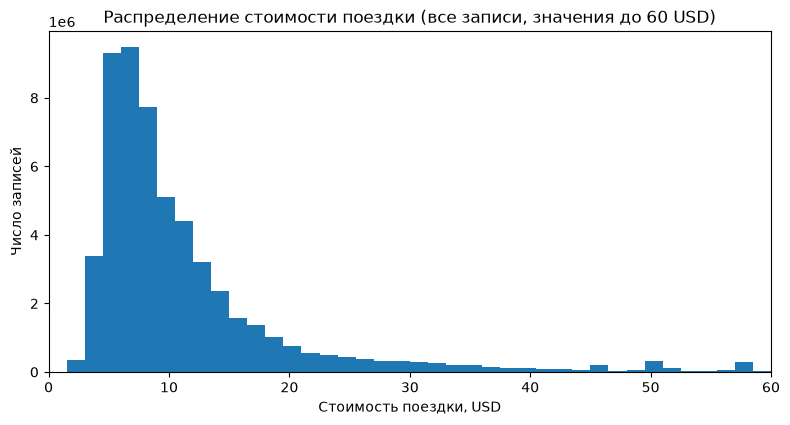

In [14]:
counts, edges = np.histogram(values, bins=40, range=(0, 60))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.stairs(counts, edges, fill=True)
ax.set_xlim(0, 60)
ax.set_xlabel("Стоимость поездки, USD")
ax.set_ylabel("Число записей")
ax.set_title("Распределение стоимости поездки (все записи, значения до 60 USD)")
fig.tight_layout()
fig.savefig("../plots/01_hist.png", dpi=150)
plt.show()

Распределение стоимости скошено вправо: пик приходится на 5–10 USD, а правый хвост тянется до 60 USD и дальше.

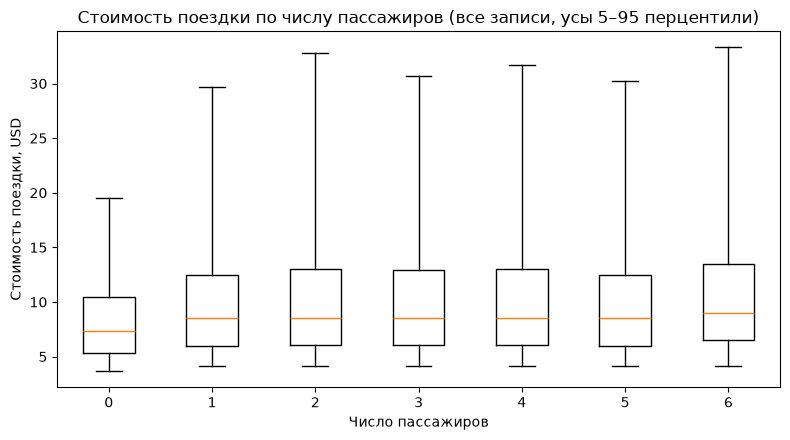

In [15]:
groups = [0, 1, 2, 3, 4, 5, 6]
qs = (
    df.groupby("passenger_count")["fare_amount"]
      .quantile([0.05, 0.25, 0.5, 0.75, 0.95])
      .unstack()
)

stats = []
for g in groups:
    row = qs.loc[g]
    stats.append({
        "label": str(g),
        "whislo": row.loc[0.05],
        "q1": row.loc[0.25],
        "med": row.loc[0.5],
        "q3": row.loc[0.75],
        "whishi": row.loc[0.95],
        "fliers": [],
    })

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bxp(stats, showfliers=False)
ax.set_xlabel("Число пассажиров")
ax.set_ylabel("Стоимость поездки, USD")
ax.set_title("Стоимость поездки по числу пассажиров (все записи, усы 5–95 перцентили)")
fig.tight_layout()
fig.savefig("../plots/02_box_groups.png", dpi=150)
plt.show()

Медианы групп 1–6 почти совпадают (около 8,5–9 USD), группа 0 немного ниже (7,3 USD), а разброс внутри групп заметно больше различий между ними.

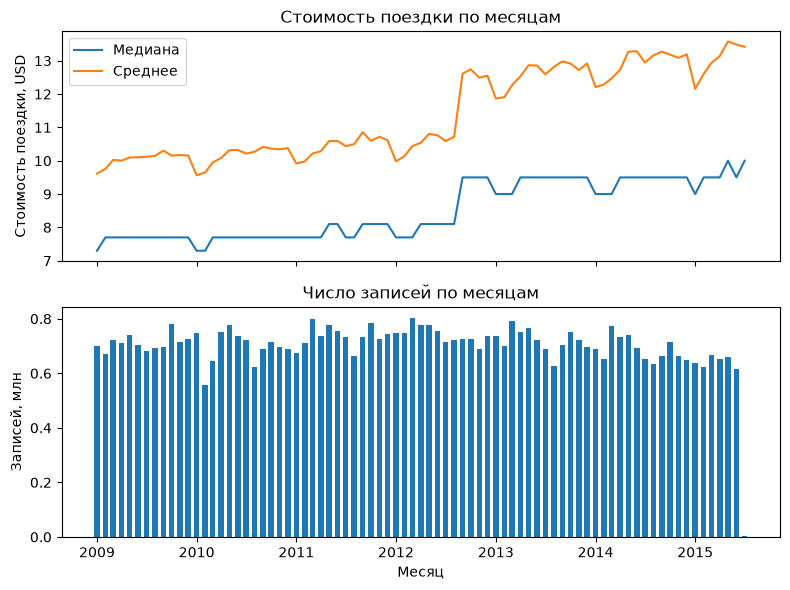

In [16]:
x = series.index.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

axes[0].plot(x, series["median_fare"], label="Медиана")
axes[0].plot(x, series["mean_fare"], label="Среднее")
axes[0].set_ylabel("Стоимость поездки, USD")
axes[0].legend()
axes[0].set_title("Стоимость поездки по месяцам")

axes[1].bar(x, series["n_records"] / 1e6, width=20)
axes[1].set_ylabel("Записей, млн")
axes[1].set_xlabel("Месяц")
axes[1].set_title("Число записей по месяцам")

fig.tight_layout()
fig.savefig("../plots/03_series.png", dpi=150)
plt.show()

Медиана стоимости растёт с 7,3 USD в январе 2009 года примерно до 10 USD в 2015 году. Последний месяц (июль 2015) неполный: записей в нём в сотни раз меньше, чем в обычные месяцы.

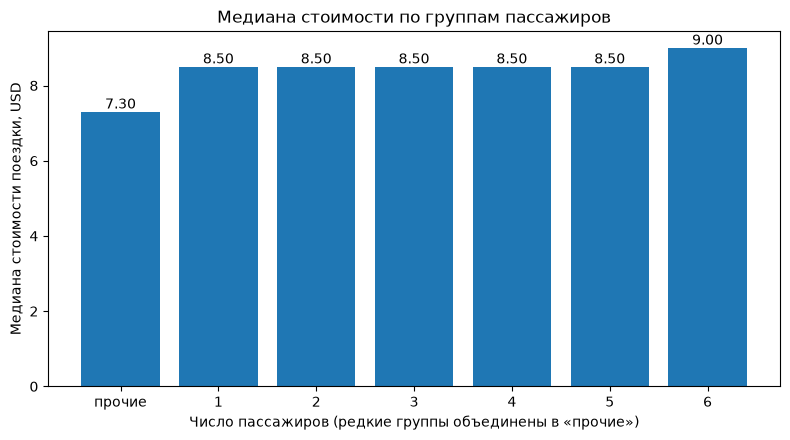

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(diagram.index, diagram["median"])
ax.bar_label(bars, fmt="%.2f")
ax.set_xlabel("Число пассажиров (редкие группы объединены в «прочие»)")
ax.set_ylabel("Медиана стоимости поездки, USD")
ax.set_title("Медиана стоимости по группам пассажиров")
fig.tight_layout()
fig.savefig("../plots/04_bar_groups.png", dpi=150)
plt.show()

Медиана стоимости у основных групп (1–6) практически одинакова, около 8,5–9 USD; группа «прочие» ниже (7,3 USD).

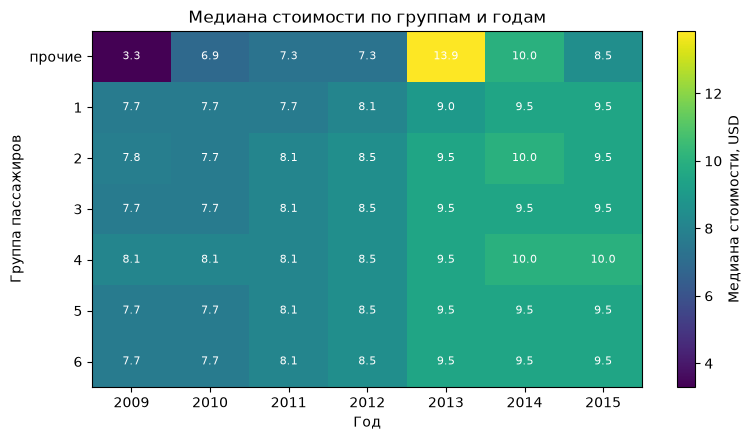

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(pivot.values, aspect="auto", cmap="viridis")

ax.set_xticks(range(pivot.shape[1]))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(pivot.shape[0]))
ax.set_yticklabels(pivot.index)

for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="white", fontsize=8)

fig.colorbar(im, ax=ax, label="Медиана стоимости, USD")
ax.set_xlabel("Год")
ax.set_ylabel("Группа пассажиров")
ax.set_title("Медиана стоимости по группам и годам")
fig.tight_layout()
fig.savefig("../plots/05_heatmap.png", dpi=150)
plt.show()

По годам цвет меняется от левого края к правому, а по строкам почти не меняется: медиана определяется годом, а не числом пассажиров.

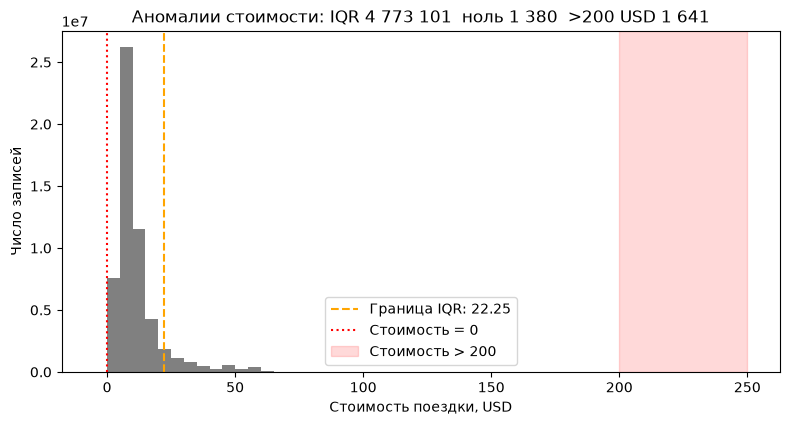

In [19]:
q1, q3 = df["fare_amount"].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr

n_zero = int((values <= 0).sum())
n_200 = int((values > 200).sum())
n_iqr = int(((values < lo) | (values > hi)).sum())

counts, edges = np.histogram(values, bins=51, range=(-5, 250))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.stairs(counts, edges, fill=True, color="grey")
ax.axvline(hi, color="orange", ls="--", label=f"Граница IQR: {hi:.2f}")
ax.axvline(0, color="red", ls=":", label="Стоимость = 0")
ax.axvspan(200, 250, color="red", alpha=0.15, label="Стоимость > 200")
ax.set_xlabel("Стоимость поездки, USD")
ax.set_ylabel("Число записей")
ax.set_title(
    f"Аномалии стоимости: IQR {n_iqr:,}, ноль {n_zero:,}, >200 USD {n_200:,}"
    .replace(",", " ")
)
ax.legend()
fig.tight_layout()
fig.savefig("../plots/06_anomalies.png", dpi=150)
plt.show()

Граница IQR (22,25 USD) отделяет основную массу дорогих поездок, которых больше всего; записи с нулевой стоимостью и выше 200 USD единичны и видны только у края распределения.